# Entrega 2 (parte B) — Modelado
**Proyecto:** Predicción de cancelaciones de reservas hoteleras
**Curso:** Aprendizaje Máquina I — Maestría en Ciencia de Datos, Universidad Panamericana

Fase 4 de CRISP-DM:

1. **Selección del modelo:** tipo de problema, métricas y esquema de validación.
2. **Regresión logística desde cero** con NumPy (modelo más simple, para mostrar cómo funciona).
3. **Entrenamiento** y comparación de modelos con validación cruzada.
4. **Ajuste de hiperparámetros.**
5. Escenario con variables sospechosas de fuga (bitácora EDA #2).
6. Umbral de decisión, evaluación única en la prueba temporal e interpretación.
7. Empaquetado del modelo final para el servidor MCP.

## 0. Configuración y datos preparados

In [1]:
import inspect
import json
import time
import warnings
from datetime import date
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import sklearn
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, StratifiedGroupKFold,
                                     cross_val_predict, cross_validate)
from sklearn.pipeline import Pipeline

import hoteles
from hoteles.datos import CAT, Y, columnas_entrada
from hoteles.estilo import (AZUL, GRIS, MORADO, NARANJA, TINTA, TINTA2, VERDE, aplicar_estilo,
                            guardar, pct)
from hoteles.logistica_numpy import RegresionLogisticaNumpy
from hoteles.preprocesamiento import construir_preprocesador

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=sklearn.exceptions.UndefinedMetricWarning)
SEED = 42
RAIZ = Path("..").resolve()
PROC, FIG, TAB, MODELOS = (RAIZ / "data" / "processed", RAIZ / "report" / "figuras",
                           RAIZ / "report" / "tablas", RAIZ / "models")
MODELOS.mkdir(exist_ok=True)
aplicar_estilo()

train = pd.read_parquet(PROC / "train.parquet")
test = pd.read_parquet(PROC / "test.parquet")
X_tr, y_tr, g_tr = train.drop(columns=[Y]), train[Y].to_numpy(), train["grupo"].to_numpy()
X_te, y_te = test.drop(columns=[Y]), test[Y].to_numpy()
print(f"Entrenamiento: {X_tr.shape}, tasa {y_tr.mean():.3f} | Prueba: {X_te.shape}, tasa {y_te.mean():.3f}")

Entrenamiento: (97033, 43), tasa 0.363 | Prueba: (22177, 43), tasa 0.406


## 1. Selección del tipo de modelo, métricas y validación

- **Tipo de problema:** la variable objetivo `is_canceled` es binaria (0/1) y está etiquetada →
  **clasificación supervisada binaria**. No es regresión (no se predice una cantidad) ni
  *clustering* (sí hay etiqueta). Interesa además la **probabilidad** de cancelación, para
  priorizar reservas por riesgo (sobreventa controlada, recordatorios, depósitos).
- **Métrica principal: PR-AUC** (*average precision*). Con 37 % de positivos la exactitud de un
  clasificador trivial ya es 63 % (bitácora #10), y el área bajo la curva precisión-*recall* se
  centra en la clase que importa. Secundarias: ROC-AUC, F1, *recall* y precisión.
- **Validación:** `StratifiedGroupKFold` con 5 pliegues dentro del entrenamiento. Estratifica por
  la clase y mantiene cada grupo de filas duplicadas en un solo pliegue (bitácora #3), así que el
  modelo no puede "memorizar" una copia y evaluarse con su gemela.
- **Prueba:** el conjunto temporal (llegadas desde mayo de 2017) se usa una sola vez, al final.
- **Desbalance:** pesos de clase `balanced` en todos los modelos, sin sobremuestreo (bitácora #10).

In [2]:
CV = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
METRICAS = {"pr_auc": "average_precision", "roc_auc": "roc_auc", "f1": "f1", "recall": "recall",
            "precision": "precision"}


def pipeline(modelo, lineal, con_sospechosas=False):
    """Preprocesamiento (ajustado en cada pliegue) + modelo."""
    return Pipeline([("prep", construir_preprocesador(lineal, con_sospechosas)), ("modelo", modelo)])


def evaluar_cv(pipe, n_jobs=1):
    t0 = time.time()
    r = cross_validate(pipe, X_tr, y_tr, groups=g_tr, cv=CV, scoring=METRICAS, n_jobs=n_jobs)
    fila = {m: r[f"test_{m}"].mean() for m in METRICAS}
    fila["pr_auc_std"] = r["test_pr_auc"].std()
    fila["segundos"] = time.time() - t0
    return fila

## 2. Regresión logística implementada desde cero (solo NumPy)

El modelo más simple se programó sin librerías de aprendizaje automático
(`src/hoteles/logistica_numpy.py`) para mostrar qué ocurre dentro del `fit`.

**Modelo.** Para una reserva con variables $x \in \mathbb{R}^d$:
$$z = w^\top x + b, \qquad \hat p = \sigma(z) = \frac{1}{1 + e^{-z}}$$
$\hat p$ es la probabilidad estimada de cancelación y $w$ indica cuánto sube o baja el
*log-odds* de cancelar por cada unidad (desviación estándar, tras escalar) de cada variable.

**Pérdida.** Entropía cruzada ponderada más penalización L2 (evita coeficientes enormes con decenas
de columnas, varias de ellas *one-hot* correlacionadas):
$$L(w,b) = -\frac{1}{\sum_i s_i}\sum_i s_i\left[y_i\log\hat p_i + (1-y_i)\log(1-\hat p_i)\right] + \frac{\lambda}{2}\lVert w\rVert^2$$
con $s_i = n / (2 n_{y_i})$ (pesos *balanced*: la clase minoritaria pesa más).

**Gradiente.** Como $\sigma'(z) = \sigma(z)(1-\sigma(z))$, la derivada se simplifica a una forma
muy compacta: el error de predicción multiplicado por la entrada:
$$\nabla_w L = \frac{1}{\sum_i s_i} X^\top\left[s \odot (\hat p - y)\right] + \lambda w, \qquad \frac{\partial L}{\partial b} = \frac{1}{\sum_i s_i}\sum_i s_i(\hat p_i - y_i)$$

**Optimización.** Descenso por gradiente con mini-lotes: en cada época se barajan las filas, se
recorren en lotes de 1,024 y se actualiza $w \leftarrow w - \eta \nabla_w L$. Se detiene cuando la
pérdida deja de bajar durante 5 épocas. Los hiperparámetros son la tasa de aprendizaje $\eta$ y
la fuerza de regularización $\lambda$.

El código del núcleo del algoritmo:

In [3]:
for metodo in (RegresionLogisticaNumpy.sigmoide, RegresionLogisticaNumpy.gradiente, RegresionLogisticaNumpy.fit):
    print(inspect.getsource(metodo))

    @staticmethod
    def sigmoide(z):
        """σ(z) numéricamente estable: evita exp de números grandes positivos o negativos."""
        z = np.asarray(z, dtype=float)
        out = np.empty_like(z)
        pos = z >= 0
        out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
        ez = np.exp(z[~pos])
        out[~pos] = ez / (1.0 + ez)
        return out

    def gradiente(self, X, y, s):
        """Gradiente analítico de la pérdida respecto a (w, b)."""
        p = self.sigmoide(X @ self.coef_ + self.intercept_)
        err = s * (p - y)
        norm = s.sum()
        return X.T @ err / norm + self.lambda_l2 * self.coef_, err.sum() / norm

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, float).ravel()
        n, d = X.shape
        rng = np.random.default_rng(self.semilla)
        s = self._pesos_muestra(y)
        self.classes_ = np.array([0, 1])
        self.coef_ = np.zeros(d)
        self.intercept_ = 0.0
        self.historial_perdida_ = [self.perdida(

### 2.1 Verificación del gradiente

Antes de entrenar se comprueba que el gradiente analítico es correcto comparándolo con una
aproximación numérica por diferencias centrales,
$\partial L/\partial w_j \approx [L(w + \varepsilon e_j) - L(w - \varepsilon e_j)] / 2\varepsilon$.

In [4]:
prep_lin = construir_preprocesador(lineal=True).fit(X_tr)
Xm = prep_lin.transform(X_tr)
nombres = prep_lin[-1].get_feature_names_out()

rng = np.random.default_rng(SEED)
muestra = rng.choice(len(Xm), 3000, replace=False)
Xs, ys = Xm[muestra], y_tr[muestra].astype(float)
rl = RegresionLogisticaNumpy(lambda_l2=1e-3)
s = rl._pesos_muestra(ys)
rl.coef_, rl.intercept_ = rng.normal(0, 0.1, Xm.shape[1]), 0.1
g_w, g_b = rl.gradiente(Xs, ys, s)

eps, filas = 1e-6, []
for j in [0, 5, 20, 40, 80]:
    w0 = rl.coef_.copy()
    rl.coef_[j] += eps; mas = rl.perdida(Xs, ys, s)
    rl.coef_[j] -= 2 * eps; menos = rl.perdida(Xs, ys, s)
    rl.coef_ = w0
    filas.append((nombres[j], g_w[j], (mas - menos) / (2 * eps)))
chequeo = pd.DataFrame(filas, columns=["coeficiente", "gradiente analítico", "gradiente numérico"])
chequeo["error relativo"] = (chequeo.iloc[:, 1] - chequeo.iloc[:, 2]).abs() / chequeo.iloc[:, 2].abs()
chequeo

,coeficiente,gradiente analítico,gradiente numérico,error relativo
0,lead_time,-0.170064,-0.170064,2.697042e-10
1,days_in_waiting_list,-0.048532,-0.048532,2.755823e-09
2,tiene_ninos,-0.051901,-0.051901,2.847566e-10
3,distribution_channel_Corporate,0.007739,0.007739,1.420525e-08
4,dia_semana_Viernes,-0.005741,-0.005741,1.292963e-08


### 2.2 Entrenamiento y comparación con la implementación de scikit-learn

Se entrena con todo el conjunto de entrenamiento (ya transformado) y se compara contra
`sklearn.linear_model.LogisticRegression`, que optimiza la misma función con un método de
segundo orden (L-BFGS). Para que ambas minimicen la misma pérdida, $C = 1/(\lambda n)$.
scikit-learn se usa **solo como verificación**; el modelo del proyecto es la versión NumPy.

In [5]:
LAMBDA = 1e-4
t0 = time.time()
rl = RegresionLogisticaNumpy(lambda_l2=LAMBDA).fit(Xm, y_tr)
t_np = time.time() - t0
t0 = time.time()
sk = LogisticRegression(C=1 / (LAMBDA * len(Xm)), class_weight="balanced", max_iter=5000).fit(Xm, y_tr)
t_sk = time.time() - t0

p_np, p_sk = rl.predict_proba(Xm)[:, 1], sk.predict_proba(Xm)[:, 1]
pd.DataFrame({
    "NumPy (descenso por gradiente)": [rl.n_epocas_, t_np, rl.historial_perdida_[-1], roc_auc_score(y_tr, p_np), average_precision_score(y_tr, p_np)],
    "scikit-learn (L-BFGS)": [sk.n_iter_[0], t_sk, np.nan, roc_auc_score(y_tr, p_sk), average_precision_score(y_tr, p_sk)],
}, index=["épocas / iteraciones", "segundos", "pérdida final", "ROC-AUC (entrenamiento)", "PR-AUC (entrenamiento)"]).round(4)

,NumPy (descenso por gradiente),scikit-learn (L-BFGS)
épocas / iteraciones,44.0000,85.0000
segundos,2.0704,1.0633
pérdida final,0.4404,NaN
ROC-AUC (entrenamiento),0.8627,0.8642
PR-AUC (entrenamiento),0.8430,0.8444


Correlación de coeficientes: 0.9226; diferencia máxima de probabilidad: 0.3277


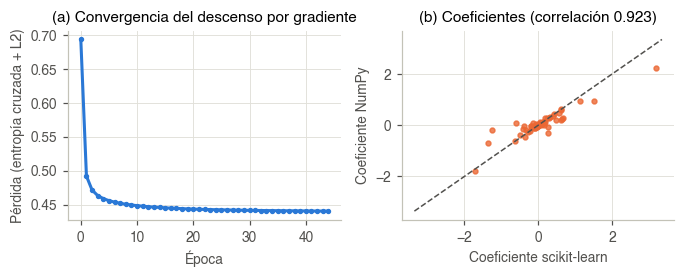

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(6.3, 2.6))
ax = axes[0]
ax.plot(range(len(rl.historial_perdida_)), rl.historial_perdida_, color=AZUL, lw=2, marker="o", ms=2.5)
ax.set_xlabel("Época")
ax.set_ylabel("Pérdida (entropía cruzada + L2)")
ax.set_title("(a) Convergencia del descenso por gradiente")
ax = axes[1]
ax.scatter(sk.coef_[0], rl.coef_, s=10, color=NARANJA, alpha=0.8)
lim = np.abs(np.r_[sk.coef_[0], rl.coef_]).max() * 1.05
ax.plot([-lim, lim], [-lim, lim], color=TINTA2, lw=1, ls="--")
ax.set_xlabel("Coeficiente scikit-learn")
ax.set_ylabel("Coeficiente NumPy")
r = np.corrcoef(sk.coef_[0], rl.coef_)[0, 1]
ax.set_title(f"(b) Coeficientes (correlación {r:.3f})")
fig.tight_layout()
guardar(fig, FIG, "fig11_logistica_numpy")
print(f"Correlación de coeficientes: {r:.4f}; diferencia máxima de probabilidad: {np.abs(p_np - p_sk).max():.4f}")

**Lectura:** el gradiente analítico coincide con el numérico (error relativo < 1e-7), así que la
derivación es correcta. La implementación NumPy converge en 44 épocas y llega prácticamente al
mismo desempeño que scikit-learn en entrenamiento (ROC-AUC 0.863 vs 0.864; PR-AUC 0.843 vs 0.844).
Los coeficientes están muy correlacionados (0.92) pero no son idénticos, por dos razones:
(1) el descenso por gradiente con mini-lotes y tasa fija se detiene *cerca* del mínimo, mientras
L-BFGS lo alcanza con más precisión; y (2) el *one-hot* sin columna de referencia más el intercepto
crea direcciones redundantes (sumar una constante a todas las columnas de una variable y restarla
al intercepto no cambia la predicción), donde una penalización tan pequeña ($\lambda = 10^{-4}$)
apenas fija una solución. Por eso las probabilidades difieren en casos aislados (máx. 0.33) aunque
el ordenamiento de las reservas, que es lo que miden las AUC, es casi el mismo. NumPy tarda un poco
más (2.1 s vs 1.1 s), lo esperable frente a un optimizador de segundo orden escrito en C.

## 3. Entrenamiento y comparación inicial (validación cruzada)

Se comparan, con hiperparámetros por defecto y en el escenario conservador:

- **Línea base:** predice la tasa de cancelación del entrenamiento para todos (PR-AUC = prevalencia).
- **Regresión logística (NumPy):** lineal, interpretable; necesita log + escalado.
- **Random Forest:** promedio de árboles profundos entrenados con *bootstrap*; captura no
  linealidades e interacciones (p. ej., depósito × segmento).
- **Gradient Boosting (HistGradientBoosting):** árboles secuenciales que corrigen el error del
  anterior; suele ser el más preciso en datos tabulares.

In [7]:
candidatos = {
    "Línea base (prevalencia)": (pipeline(DummyClassifier(strategy="prior"), lineal=False), 1),
    "Regresión logística (NumPy)": (pipeline(RegresionLogisticaNumpy(), lineal=True), 5),
    "Random Forest": (pipeline(RandomForestClassifier(n_estimators=200, min_samples_leaf=2, class_weight="balanced_subsample",
                                                      n_jobs=-1, random_state=SEED), lineal=False), 1),
    "Gradient Boosting (HGB)": (pipeline(HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED), lineal=False), 1),
}
inicial = pd.DataFrame({n: evaluar_cv(p, n_jobs=j) for n, (p, j) in candidatos.items()}).T
inicial.round(3)

,pr_auc,roc_auc,f1,recall,precision,pr_auc_std,segundos
Línea base (prevalencia),0.363,0.500,0.000,0.000,0.000,0.011,10.994
Regresión logística (NumPy),0.841,0.861,0.725,0.718,0.732,0.010,14.184
Random Forest,0.873,0.896,0.764,0.710,0.827,0.010,23.213
Gradient Boosting (HGB),0.867,0.892,0.759,0.726,0.795,0.009,21.399


**Lectura:** los tres modelos superan con holgura a la línea base (PR-AUC 0.36). Con parámetros
por defecto, los modelos de árboles (Random Forest 0.873, *Gradient Boosting* 0.867) superan a la
logística (0.841) por 3 puntos de PR-AUC, como anticipaba el EDA (§9: señal repartida y no
lineal, interacciones como depósito × segmento). La desviación estándar entre pliegues (≈ 0.01)
indica que la diferencia entre árboles y logística es mayor que el ruido de la validación; entre
RF y HGB no.

## 4. Ajuste de hiperparámetros

Toda búsqueda usa la misma validación cruzada agrupada y optimiza PR-AUC. El preprocesamiento
está dentro del Pipeline, así que se reajusta en cada pliegue (sin fuga).

| Modelo | Búsqueda | Hiperparámetros |
|---|---|---|
| Logística NumPy | Rejilla completa (12 combinaciones × 5 pliegues) | tasa de aprendizaje $\eta$, regularización $\lambda$ |
| Gradient Boosting | Aleatoria (20 combinaciones × 5 pliegues) | tasa de aprendizaje, hojas por árbol, mínimo de muestras por hoja, L2, fracción de variables (con parada temprana) |
| Random Forest | Aleatoria (6 combinaciones × 5 pliegues; es el más costoso) | número de árboles, profundidad, mínimo por hoja, variables por división |

In [8]:
t0 = time.time()
busq_lr = GridSearchCV(pipeline(RegresionLogisticaNumpy(), lineal=True),
                       {"modelo__tasa_aprendizaje": [0.03, 0.1, 0.3],
                        "modelo__lambda_l2": [1e-5, 1e-4, 1e-3, 1e-2]},
                       scoring=METRICAS, refit="pr_auc", cv=CV, n_jobs=5).fit(X_tr, y_tr, groups=g_tr)
print(f"Logística NumPy: {time.time() - t0:.0f} s, mejor PR-AUC {busq_lr.best_score_:.4f}, {busq_lr.best_params_}")

Logística NumPy: 38 s, mejor PR-AUC 0.8416, {'modelo__lambda_l2': 1e-05, 'modelo__tasa_aprendizaje': 0.3}


In [9]:
t0 = time.time()
hgb = HistGradientBoostingClassifier(class_weight="balanced", max_iter=600, early_stopping=True,
                                     n_iter_no_change=20, random_state=SEED)
busq_hgb = RandomizedSearchCV(pipeline(hgb, lineal=False),
                              {"modelo__learning_rate": loguniform(0.02, 0.3),
                               "modelo__max_leaf_nodes": randint(15, 128),
                               "modelo__min_samples_leaf": randint(10, 200),
                               "modelo__l2_regularization": loguniform(1e-3, 10),
                               "modelo__max_features": uniform(0.3, 0.7)},
                              n_iter=20, scoring=METRICAS, refit="pr_auc", cv=CV, n_jobs=1,
                              random_state=SEED).fit(X_tr, y_tr, groups=g_tr)
print(f"HGB: {time.time() - t0:.0f} s, mejor PR-AUC {busq_hgb.best_score_:.4f}")
busq_hgb.best_params_

HGB: 1158 s, mejor PR-AUC 0.8733


{'modelo__l2_regularization': 5.872283616443723,
 'modelo__learning_rate': 0.09194081411309145,
 'modelo__max_features': 0.5697915517779413,
 'modelo__max_leaf_nodes': 104,
 'modelo__min_samples_leaf': 62}

In [10]:
t0 = time.time()
rf = RandomForestClassifier(class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
busq_rf = RandomizedSearchCV(pipeline(rf, lineal=False),
                             {"modelo__n_estimators": [150, 250],
                              "modelo__max_depth": [None, 20, 30],
                              "modelo__min_samples_leaf": [1, 2, 5, 10],
                              "modelo__max_features": ["sqrt", 0.25, 0.4]},
                             n_iter=6, scoring=METRICAS, refit="pr_auc", cv=CV, n_jobs=1,
                             random_state=SEED).fit(X_tr, y_tr, groups=g_tr)
print(f"Random Forest: {time.time() - t0:.0f} s, mejor PR-AUC {busq_rf.best_score_:.4f}")
busq_rf.best_params_

Random Forest: 95 s, mejor PR-AUC 0.8726


{'modelo__n_estimators': 150,
 'modelo__min_samples_leaf': 2,
 'modelo__max_features': 'sqrt',
 'modelo__max_depth': 30}

In [11]:
ajustados = {"Regresión logística (NumPy)": busq_lr, "Random Forest": busq_rf, "Gradient Boosting (HGB)": busq_hgb}
filas = []
for nombre, b in ajustados.items():
    res = b.cv_results_
    i = b.best_index_
    fila = {"modelo": nombre, "PR-AUC por defecto": inicial.loc[nombre, "pr_auc"]}
    fila.update({m: res[f"mean_test_{m}"][i] for m in METRICAS})
    fila["pr_auc_std"] = res["std_test_pr_auc"][i]
    fila["mejores hiperparámetros"] = ", ".join(f"{k.replace('modelo__', '')}={v:.3g}" if isinstance(v, float) else f"{k.replace('modelo__', '')}={v}"
                                                for k, v in b.best_params_.items())
    filas.append(fila)
tuneo = pd.DataFrame(filas).set_index("modelo")
with open(TAB / "modelos_cv.tex", "w") as f:
    f.write(f"Línea base (prevalencia) & -- & {inicial.loc['Línea base (prevalencia)', 'pr_auc']:.3f} & {inicial.loc['Línea base (prevalencia)', 'roc_auc']:.3f} & -- & -- & -- \\\\\n")
    for n, r in tuneo.iterrows():
        f.write(f"{n} & {r['PR-AUC por defecto']:.3f} & {r['pr_auc']:.3f} $\\pm$ {r['pr_auc_std']:.3f} & {r['roc_auc']:.3f} & "
                f"{r['f1']:.3f} & {r['recall']:.3f} & {r['precision']:.3f} \\\\\n")
with open(TAB / "hiperparametros.tex", "w") as f:
    for n, r in tuneo.iterrows():
        f.write(f"{n} & \\texttt{{{r['mejores hiperparámetros'].replace('_', chr(92) + '_')}}} \\\\\n")
tuneo.round(4)

,PR-AUC por defecto,pr_auc,roc_auc,f1,recall,precision,pr_auc_std,mejores hiperparámetros
modelo,,,,,,,,
Regresión logística (NumPy),0.8411,0.8416,0.8613,0.7251,0.7224,0.7282,0.0103,"lambda_l2=1e-05, tasa_aprendizaje=0.3"
Random Forest,0.8728,0.8726,0.8958,0.7641,0.7125,0.8237,0.0098,"n_estimators=150, min_samples_leaf=2, max_feat..."
Gradient Boosting (HGB),0.8673,0.8733,0.8962,0.7687,0.7531,0.7849,0.0097,"l2_regularization=5.87, learning_rate=0.0919, ..."


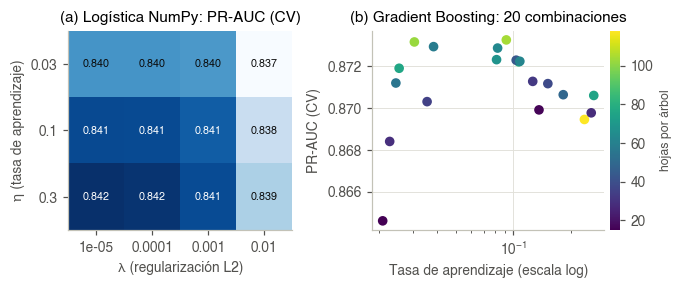

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(6.3, 2.7), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
res = pd.DataFrame(busq_lr.cv_results_)
mapa = res.pivot_table(index="param_modelo__tasa_aprendizaje", columns="param_modelo__lambda_l2", values="mean_test_pr_auc")
im = ax.imshow(mapa.values, cmap="Blues", aspect="auto")
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        v = mapa.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=7,
                color="white" if v > np.nanmean(mapa.values) else TINTA)
ax.set_xticks(range(mapa.shape[1]), [f"{c:g}" for c in mapa.columns])
ax.set_yticks(range(mapa.shape[0]), [f"{c:g}" for c in mapa.index])
ax.set_xlabel("λ (regularización L2)")
ax.set_ylabel("η (tasa de aprendizaje)")
ax.set_title("(a) Logística NumPy: PR-AUC (CV)")
ax.grid(False)
ax = axes[1]
res = pd.DataFrame(busq_hgb.cv_results_)
sc = ax.scatter(res["param_modelo__learning_rate"].astype(float), res["mean_test_pr_auc"],
                c=res["param_modelo__max_leaf_nodes"].astype(float), cmap="viridis", s=28)
ax.set_xscale("log")
ax.set_xlabel("Tasa de aprendizaje (escala log)")
ax.set_ylabel("PR-AUC (CV)")
ax.set_title("(b) Gradient Boosting: 20 combinaciones")
cb = fig.colorbar(sc, ax=ax, pad=0.02)
cb.set_label("hojas por árbol", fontsize=8)
cb.outline.set_visible(False)
fig.tight_layout()
guardar(fig, FIG, "fig12_hiperparametros")

In [13]:
# Interpretación de la logística NumPy ajustada: coeficientes sobre variables estandarizadas.
lr_final = busq_lr.best_estimator_
coefs = pd.Series(lr_final["modelo"].coef_, index=lr_final["prep"][-1].get_feature_names_out())
pd.concat([coefs.nlargest(8).rename("aumenta el riesgo"), coefs.nsmallest(8).rename("reduce el riesgo")], axis=1).round(2)

,aumenta el riesgo,reduce el riesgo
deposit_type_Non Refund,2.60,NaN
tasa_cancelacion_previa,1.12,NaN
agent_A240,1.06,NaN
customer_type_Transient,0.63,NaN
lead_time,0.62,NaN
distribution_channel_Corporate,0.51,NaN
frecuencia_agente,0.49,NaN
meal_infrequent_sklearn,0.45,NaN
deposit_type_No Deposit,NaN,-1.94
agent_A28,NaN,-0.96


**Lectura:**

- **Logística NumPy:** la mejor combinación es la tasa de aprendizaje más alta (η = 0.3) con la
  regularización más débil (λ = 1e-5). Una λ de 1e-2 baja el PR-AUC de forma visible (mapa a):
  con 97 mil filas y 81 columnas el modelo está lejos del sobreajuste; lo que le falta es
  capacidad para representar no linealidades. El ajuste casi no cambia nada (0.841 → 0.842).
- **Gradient Boosting:** es el que más gana con el ajuste (0.867 → 0.873): árboles grandes
  (≈ 100 hojas) con al menos ≈ 60 reservas por hoja, tasa de aprendizaje ≈ 0.09, regularización
  L2 fuerte (5.9) y poco más de la mitad de las variables por división.
- **Random Forest:** su configuración por defecto ya era casi óptima (0.8728 → 0.8726).
- HGB y RF empatan en validación (0.8733 vs 0.8726, diferencia muy inferior a la desviación de
  0.01). Se elige **HGB** como modelo final por su mayor PR-AUC, ROC-AUC y *recall*, y porque el
  artefacto es mucho más ligero para el servidor (3 MB contra cientos de MB de un bosque profundo).
- **Coeficientes de la logística** (variables estandarizadas): `deposit_type = Non Refund` es el
  mayor factor de riesgo, seguido de la tasa de cancelación previa, la agencia 240, el cliente
  *Transient* y la anticipación; la nueva `frecuencia_agente` también aparece entre las que suben
  el riesgo. Lo reducen `No Deposit` frente a `Non Refund`, algunas agencias concretas y las
  solicitudes especiales (quien pide algo planea llegar).

## 5. Escenario con variables sospechosas de fuga

Bitácora #2: `country`, `required_car_parking_spaces` y `booking_changes` podrían registrarse
después del día de observación (al llegar el huésped). Se vuelve a evaluar el mejor modelo de árboles,
con los mismos hiperparámetros, agregándolas. Si la métrica sube mucho, es una señal de que
dependen del desenlace y no estarían disponibles el día anterior a la llegada, que es cuando se
predice (Entrega 1, §I-B).

In [14]:
mejor_arbol = "Gradient Boosting (HGB)" if busq_hgb.best_score_ >= busq_rf.best_score_ else "Random Forest"
pipe_cons = ajustados[mejor_arbol].best_estimator_
pipe_sosp = clone(pipe_cons).set_params(prep=construir_preprocesador(lineal=False, con_sospechosas=True))
escenarios = pd.DataFrame({
    "Conservador (sin sospechosas)": tuneo.loc[mejor_arbol, list(METRICAS)],
    "Completo (con sospechosas)": pd.Series(evaluar_cv(pipe_sosp))[list(METRICAS)],
}).T.astype(float)
escenarios.loc["Diferencia"] = escenarios.iloc[1] - escenarios.iloc[0]
print("Modelo:", mejor_arbol)
escenarios.round(4)

Modelo: Gradient Boosting (HGB)


,pr_auc,roc_auc,f1,recall,precision
Conservador (sin sospechosas),0.8733,0.8962,0.7687,0.7531,0.7849
Completo (con sospechosas),0.9258,0.9505,0.8316,0.8502,0.8138
Diferencia,0.0526,0.0543,0.0629,0.0971,0.0289


**Lectura:** agregar `country`, `required_car_parking_spaces` y `booking_changes` sube el PR-AUC
de 0.873 a 0.926 (+5.3 puntos) y el *recall* en 9.7 puntos. Es una mejora demasiado grande para
tres variables, coherente con la sospecha del EDA: el estacionamiento separa perfectamente (nadie
que lo pidió canceló) porque probablemente se registra al llegar, y el país se corrige en el
*check-in*. Ese desempeño **no estaría disponible en operación**: el día anterior a la llegada,
que es cuando se predice, esos valores todavía no existen o no son definitivos. El modelo final se
queda en el escenario **conservador**; el completo se reporta solo como cota superior (OE1).

## 6. Modelo final y umbral de decisión según el costo de los errores

Se elige el modelo con mayor PR-AUC en validación cruzada (no en prueba). Para convertir la
probabilidad en una decisión, el OE4 de la Entrega 1 pide un umbral **según lo que cuesta cada
tipo de error**. La acción que dispara una predicción positiva es sobrevender esa habitación:

| Caso | Qué pasa | Costo supuesto |
|---|---|---|
| Falso negativo | La reserva se cancela y nadie lo anticipó: la habitación queda vacía | ingreso de la reserva, $c_{FN} = ADR \times noches$ |
| Falso positivo | Se sobrevende, pero el huésped sí llega y hay que reubicarlo en otro hotel | $c_{FP} = \kappa \cdot ADR \times noches$ |
| Verdadero positivo / negativo | Se revende la habitación / no se hace nada | 0 |

Reubicar a un huésped cuesta más que su propia tarifa (habitación en otro hotel, traslado,
compensación y riesgo reputacional), así que se toma **κ = 1.5** como supuesto base y se analiza
la sensibilidad con κ ∈ {1, 1.5, 2, 3}. El umbral minimiza el costo total sobre las
**predicciones fuera de pliegue** del entrenamiento (cada reserva la predice un modelo que no la
vio), sin tocar la prueba. Con probabilidades perfectamente calibradas el umbral óptimo sería
$\kappa/(1+\kappa)$; como los pesos *balanced* desplazan las probabilidades, se busca de forma
empírica.

In [15]:
mejor_nombre = tuneo["pr_auc"].idxmax()
final = ajustados[mejor_nombre].best_estimator_
oof = cross_val_predict(clone(final), X_tr, y_tr, groups=g_tr, cv=CV, method="predict_proba")[:, 1]

limite_adr = final["prep"].named_steps["recorte"].limites_["adr"]
ingreso_tr = (train["adr"].clip(0, limite_adr) * train["noches"].clip(lower=1)).to_numpy()
UMBRALES = np.round(np.arange(0.05, 0.951, 0.005), 3)
KAPPAS = [1.0, 1.5, 2.0, 3.0]
KAPPA = 1.5


def costo_total(p, y, ingreso, t, kappa):
    pred = p >= t
    return ingreso[~pred & (y == 1)].sum() + kappa * ingreso[pred & (y == 0)].sum()


costo_sin_modelo = ingreso_tr[y_tr == 1].sum()  # no sobrevender nunca: toda cancelación es pérdida
curvas = {k: np.array([costo_total(oof, y_tr, ingreso_tr, t, k) for t in UMBRALES]) / costo_sin_modelo for k in KAPPAS}
filas = []
for k in KAPPAS:
    t = UMBRALES[np.argmin(curvas[k])]
    pred = oof >= t
    filas.append({"kappa": k, "umbral óptimo": t, "recall": recall_score(y_tr, pred), "precision": precision_score(y_tr, pred),
                  "costo vs sin modelo": curvas[k].min(), "ahorro": 1 - curvas[k].min()})
sensibilidad = pd.DataFrame(filas).set_index("kappa")
UMBRAL = float(sensibilidad.loc[KAPPA, "umbral óptimo"])

prec, rec, umbrales_pr = precision_recall_curve(y_tr, oof)
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
UMBRAL_F1 = float(umbrales_pr[np.argmax(f1s)])
with open(TAB / "umbral.tex", "w") as f:
    for k, r in sensibilidad.iterrows():
        f.write(f"{k:g} & {r['umbral óptimo']:.3f} & {r['recall']:.3f} & {r['precision']:.3f} & {pct(r['ahorro'])} \\\\\n")
print(f"Modelo final: {mejor_nombre}")
print(f"Umbral por costos (kappa = {KAPPA}): {UMBRAL:.3f} | umbral que maximiza F1: {UMBRAL_F1:.3f}")
sensibilidad.round(3)

Modelo final: Gradient Boosting (HGB)
Umbral por costos (kappa = 1.5): 0.720 | umbral que maximiza F1: 0.501


,umbral óptimo,recall,precision,costo vs sin modelo,ahorro
kappa,,,,,
1.0,0.62,0.698,0.841,0.474,0.526
1.5,0.72,0.645,0.886,0.533,0.467
2.0,0.76,0.617,0.906,0.575,0.425
3.0,0.83,0.553,0.940,0.630,0.370


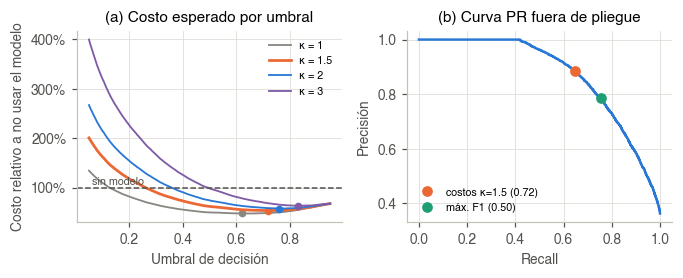

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(6.3, 2.6))
ax = axes[0]
for k, c in zip(KAPPAS, [GRIS, NARANJA, AZUL, MORADO]):
    ax.plot(UMBRALES, curvas[k], color=c, lw=1.8 if k == KAPPA else 1.2, label=f"κ = {k:g}")
    t = sensibilidad.loc[k, "umbral óptimo"]
    ax.plot(t, curvas[k].min(), "o", color=c, ms=4)
ax.axhline(1, color=TINTA2, ls="--", lw=1)
ax.text(0.06, 1.01, "sin modelo", fontsize=7, color=TINTA2, va="bottom")
ax.set(xlabel="Umbral de decisión", ylabel="Costo relativo a no usar el modelo", title="(a) Costo esperado por umbral")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.legend(fontsize=7)
ax = axes[1]
ax.plot(rec, prec, color=AZUL, lw=1.6)
for t, etq, c in [(UMBRAL, f"costos κ={KAPPA:g} ({UMBRAL:.2f})", NARANJA), (UMBRAL_F1, f"máx. F1 ({UMBRAL_F1:.2f})", VERDE)]:
    pred = oof >= t
    ax.plot(recall_score(y_tr, pred), precision_score(y_tr, pred), "o", color=c, ms=6, label=etq)
ax.set(xlabel="Recall", ylabel="Precisión", title="(b) Curva PR fuera de pliegue")
ax.legend(fontsize=7, loc="lower left")
fig.tight_layout()
guardar(fig, FIG, "fig15_umbral_costos")

**Lectura:** con el supuesto base (reubicar cuesta 1.5 veces el ingreso de la reserva) el umbral
óptimo es **0.72**, bastante más alto que el que maximiza F1 (0.50). Es lo esperable: si un falso
positivo cuesta más que un falso negativo, conviene sobrevender solo cuando el modelo está muy
seguro. Con ese umbral, en validación cruzada se detecta 65 % de las cancelaciones con una precisión
de 89 % y el costo baja 47 % frente a no usar el modelo. El análisis de sensibilidad muestra que la
decisión depende del supuesto: con κ = 1 el umbral baja a 0.62 (ahorro de 53 %) y con κ = 3 sube a
0.83 (ahorro de 37 %). El valor de κ debe fijarlo el hotel con sus costos reales de reubicación.

## 7. Evaluación final en la prueba temporal

Primera y única vez que se usan las llegadas de mayo a agosto de 2017. Se reportan todos los
modelos ajustados (para la discusión) y el escenario con sospechosas, pero la selección ya se hizo
arriba con validación cruzada.

In [17]:
def metricas_prueba(p, umbral):
    pred = (p >= umbral).astype(int)
    return {"pr_auc": average_precision_score(y_te, p), "roc_auc": roc_auc_score(y_te, p),
            "f1": f1_score(y_te, pred), "recall": recall_score(y_te, pred),
            "precision": precision_score(y_te, pred), "exactitud": accuracy_score(y_te, pred)}


probs = {n: b.best_estimator_.predict_proba(X_te)[:, 1] for n, b in ajustados.items()}
probs[f"{mejor_arbol} con sospechosas"] = pipe_sosp.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]
prueba = pd.DataFrame({n: metricas_prueba(p, UMBRAL if n == mejor_nombre else 0.5) for n, p in probs.items()}).T
prueba.loc["Línea base (prevalencia)"] = [y_te.mean(), 0.5, np.nan, np.nan, np.nan, 1 - y_te.mean()]
with open(TAB / "prueba.tex", "w") as f:
    for n, r in prueba.iterrows():
        f.write(f"{n} & " + " & ".join("--" if pd.isna(v) else f"{v:.3f}" for v in r.values) + " \\\\\n")
prueba.round(3)

,pr_auc,roc_auc,f1,recall,precision,exactitud
Regresión logística (NumPy),0.785,0.811,0.684,0.695,0.673,0.739
Random Forest,0.787,0.821,0.633,0.530,0.787,0.751
Gradient Boosting (HGB),0.784,0.816,0.602,0.479,0.808,0.743
Gradient Boosting (HGB) con sospechosas,0.834,0.876,0.716,0.661,0.780,0.787
Línea base (prevalencia),0.406,0.500,NaN,NaN,NaN,0.594


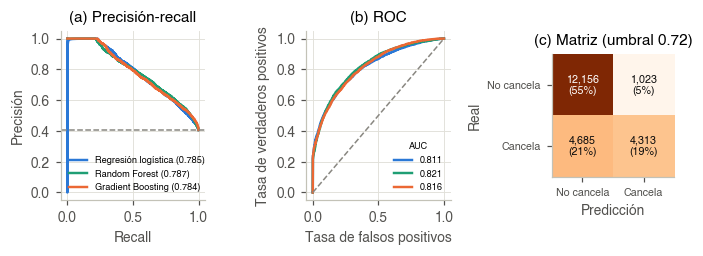

In [18]:
p_final = probs[mejor_nombre]
fig, axes = plt.subplots(1, 3, figsize=(6.3, 2.4), gridspec_kw={"width_ratios": [1, 1, 0.85]})
colores = {"Regresión logística (NumPy)": AZUL, "Random Forest": VERDE, "Gradient Boosting (HGB)": NARANJA}
for n, c in colores.items():
    pr, rc, _ = precision_recall_curve(y_te, probs[n])
    axes[0].plot(rc, pr, color=c, lw=1.6, label=f"{n.split(' (')[0]} ({average_precision_score(y_te, probs[n]):.3f})")
    fpr, tpr, _ = roc_curve(y_te, probs[n])
    axes[1].plot(fpr, tpr, color=c, lw=1.6, label=f"{roc_auc_score(y_te, probs[n]):.3f}")
axes[0].axhline(y_te.mean(), color=GRIS, ls="--", lw=1)
axes[0].set(xlabel="Recall", ylabel="Precisión", title="(a) Precisión-recall")
axes[0].legend(fontsize=6, loc="lower left")
axes[1].plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1)
axes[1].set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos", title="(b) ROC")
axes[1].legend(fontsize=6, loc="lower right", title="AUC", title_fontsize=6)
cm = confusion_matrix(y_te, p_final >= UMBRAL)
ax = axes[2]
ax.imshow(cm, cmap="Oranges")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n({cm[i, j] / cm.sum():.0%})", ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > cm.max() / 2 else TINTA)
ax.set_xticks([0, 1], ["No cancela", "Cancela"], fontsize=7)
ax.set_yticks([0, 1], ["No cancela", "Cancela"], fontsize=7)
ax.set(xlabel="Predicción", ylabel="Real", title=f"(c) Matriz (umbral {UMBRAL:.2f})")
ax.grid(False)
fig.tight_layout()
guardar(fig, FIG, "fig13_prueba")

In [19]:
# Desempeño por hotel (bitácora EDA §4: las tasas difieren mucho entre hoteles).
filas = []
for h in ["City Hotel", "Resort Hotel"]:
    m = (test["hotel"] == h).to_numpy()
    pred = p_final[m] >= UMBRAL
    filas.append({"hotel": h, "reservas": m.sum(), "tasa real": y_te[m].mean(), "tasa predicha": pred.mean(),
                  "pr_auc": average_precision_score(y_te[m], p_final[m]), "roc_auc": roc_auc_score(y_te[m], p_final[m]),
                  "recall": recall_score(y_te[m], pred), "precision": precision_score(y_te[m], pred)})
por_hotel = pd.DataFrame(filas).set_index("hotel")
por_hotel.round(3)

,reservas,tasa real,tasa predicha,pr_auc,roc_auc,recall,precision
hotel,,,,,,,
City Hotel,15191,0.426,0.297,0.812,0.825,0.559,0.802
Resort Hotel,6986,0.362,0.118,0.712,0.798,0.275,0.843


In [20]:
# Traducción a los KPIs del negocio (Entrega 1, §2): ingreso en riesgo = ADR x noches.
ingreso = test["adr"].clip(lower=0) * test["noches"]
pred = p_final >= UMBRAL
cancel = y_te == 1
negocio = pd.Series({
    "Cancelaciones reales en prueba": int(cancel.sum()),
    "Cancelaciones anticipadas por el modelo": int((pred & cancel).sum()),
    "Falsas alarmas (no cancelaron)": int((pred & ~cancel).sum()),
    "Ingreso en riesgo total (millones)": ingreso[cancel].sum() / 1e6,
    "Ingreso en riesgo anticipado (millones)": ingreso[pred & cancel].sum() / 1e6,
    "% del ingreso en riesgo anticipado": ingreso[pred & cancel].sum() / ingreso[cancel].sum(),
    "Habitaciones-noche canceladas anticipadas": int(test.loc[pred & cancel, "noches"].sum()),
    f"Costo con el modelo vs sin modelo (κ = {KAPPA:g})": costo_total(
        p_final, y_te, (test["adr"].clip(0, limite_adr) * test["noches"].clip(lower=1)).to_numpy(), UMBRAL, KAPPA)
        / (test["adr"].clip(0, limite_adr) * test["noches"].clip(lower=1))[cancel].sum(),
})
negocio.round(3)

Cancelaciones reales en prueba                  8998.000
Cancelaciones anticipadas por el modelo         4313.000
Falsas alarmas (no cancelaron)                  1023.000
Ingreso en riesgo total (millones)                 4.987
Ingreso en riesgo anticipado (millones)            2.233
% del ingreso en riesgo anticipado                 0.448
Habitaciones-noche canceladas anticipadas      15879.000
Costo con el modelo vs sin modelo (κ = 1.5)        0.720
dtype: float64

,media,std
deposit_type,0.2335,0.0058
total_of_special_requests,0.0666,0.0032
agent,0.0389,0.0036
lead_time,0.0353,0.0036
customer_type,0.0343,0.0011
market_segment,0.0203,0.0011
adr,0.0057,0.0010
adr_por_persona,0.0039,0.0005
previous_bookings_not_canceled,0.0034,0.0014
stays_in_week_nights,0.0028,0.0005


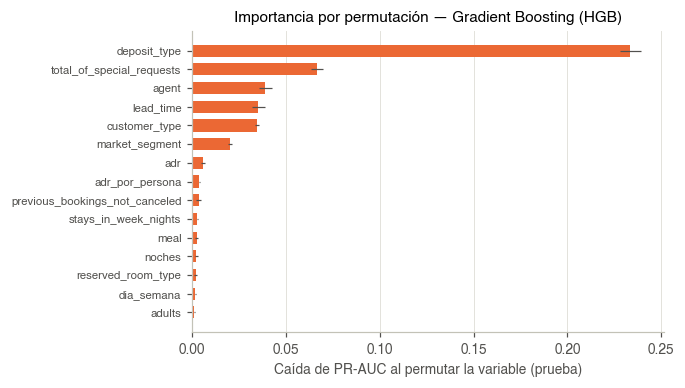

In [21]:
entrada = columnas_entrada(False)
idx = np.random.default_rng(SEED).choice(len(X_te), 6000, replace=False)
imp = permutation_importance(final, X_te.iloc[idx][entrada], y_te[idx], scoring="average_precision",
                             n_repeats=5, random_state=SEED, n_jobs=1)
importancia = pd.DataFrame({"media": imp.importances_mean, "std": imp.importances_std}, index=entrada).sort_values("media")
top = importancia.tail(15)
fig, ax = plt.subplots(figsize=(6.3, 3.6))
ax.barh(top.index, top["media"], xerr=top["std"], color=NARANJA, height=0.65, error_kw={"lw": 0.8, "ecolor": TINTA2})
ax.set_xlabel("Caída de PR-AUC al permutar la variable (prueba)")
ax.set_title(f"Importancia por permutación — {mejor_nombre}")
ax.tick_params(axis="y", labelsize=7.5)
ax.grid(axis="y", visible=False)
fig.tight_layout()
guardar(fig, FIG, "fig14_importancia")
importancia.sort_values("media", ascending=False).head(10).round(4)

### 7.1 Valores SHAP

La importancia por permutación dice cuánto empeora el modelo si se "rompe" una variable, pero no
en qué dirección empuja la predicción. Los valores SHAP (Lundberg y Lee, 2017) reparten la
predicción de cada reserva (en *log-odds*) entre sus variables, de forma que la suma de las
contribuciones más el valor base da exactamente la salida del modelo. Se calculan con
`TreeExplainer` sobre 2,000 reservas de prueba y, para comparar con la permutación, las columnas
*one-hot* se suman de vuelta a su variable original.

In [22]:
import shap

idx_shap = idx[:2000]
X_shap = pd.DataFrame(final["prep"].transform(X_te.iloc[idx_shap]), columns=final["prep"][-1].get_feature_names_out())
explicador = shap.TreeExplainer(final["modelo"])
valores = explicador.shap_values(X_shap)
valores = valores[1] if isinstance(valores, list) else valores
p_modelo = final["modelo"].predict_proba(X_shap)[:, 1]
recon = 1 / (1 + np.exp(-(valores.sum(1) + np.ravel(explicador.expected_value)[-1])))
print(f"Aditividad: error máximo al reconstruir la probabilidad con SHAP = {np.abs(recon - p_modelo).max():.2e}")


def variable_origen(col):
    candidatas = [c for c in CAT if col.startswith(c + "_")]
    return max(candidatas, key=len) if candidatas else col


por_variable = pd.DataFrame(valores, columns=X_shap.columns).T.groupby(variable_origen).sum().T
shap_medio = por_variable.abs().mean().sort_values(ascending=False)
top10 = pd.DataFrame({
    "SHAP medio |log-odds|": shap_medio.head(10).round(3),
    "posición SHAP": range(1, 11),
})
rank_perm = importancia["media"].rank(ascending=False).astype(int)
top10["posición permutación"] = [rank_perm.get(v, rank_perm.get("agent") if v == "frecuencia_agente" else np.nan) for v in top10.index]
with open(TAB / "top10.tex", "w") as f:
    for v, r in top10.iterrows():
        f.write(f"{r['posición SHAP']} & \\texttt{{{v.replace('_', chr(92) + '_')}}} & {r['SHAP medio |log-odds|']:.3f} & {r['posición permutación']} \\\\\n")
top10

Aditividad: error máximo al reconstruir la probabilidad con SHAP = 3.78e-13


,SHAP medio |log-odds|,posición SHAP,posición permutación
deposit_type,1.710,1,1
total_of_special_requests,0.735,2,2
lead_time,0.500,3,4
frecuencia_agente,0.374,4,3
customer_type,0.349,5,5
tasa_cancelacion_previa,0.258,6,20
market_segment,0.238,7,6
adr,0.155,8,7
mes_cos,0.121,9,37
agent,0.112,10,3


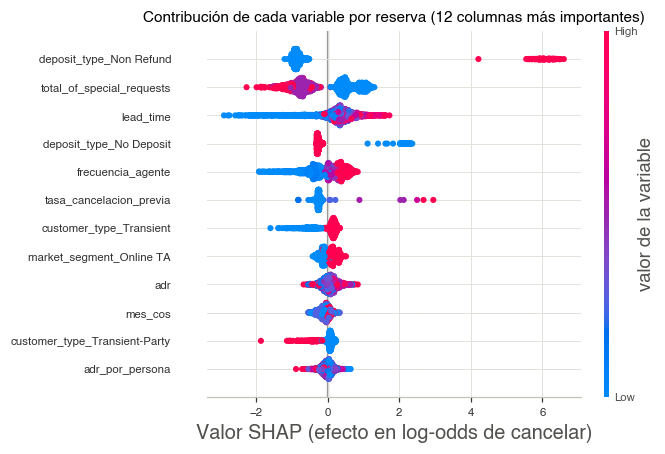

In [23]:
plt.figure()
shap.summary_plot(valores, X_shap, max_display=12, show=False, plot_size=(6.3, 4.2), color_bar_label="valor de la variable")
fig = plt.gcf()
for ax in fig.axes:
    ax.tick_params(labelsize=7.5)
fig.axes[0].set_xlabel("Valor SHAP (efecto en log-odds de cancelar)")
fig.axes[0].set_title("Contribución de cada variable por reserva (12 columnas más importantes)")
fig.tight_layout()
guardar(fig, FIG, "fig16_shap")

**Lectura:** los valores SHAP son exactos para este modelo (la suma reconstruye la probabilidad
con error de 1e-13) y su top 10 coincide con el de permutación en las primeras posiciones:
`deposit_type`, `total_of_special_requests`, `lead_time`, la agencia (`frecuencia_agente` y
`agent`), `customer_type` y `market_segment`. El gráfico añade la dirección: valores altos de
`lead_time` empujan hacia cancelar, y cada solicitud especial empuja en contra. Hay dos diferencias
que se explican por la correlación entre variables. `tasa_cancelacion_previa` es 6.ª en SHAP pero
20.ª en permutación porque `previous_cancellations` lleva casi la misma información: al permutar
una, el modelo se apoya en la otra. Y `mes_cos` (9.ª en SHAP) contribuye a cada predicción, pero
romperla cuesta poco porque la semana del año y el día del mes repiten la estacionalidad. La
frecuencia de agencia, la variable que se agregó en esta entrega, queda 4.ª: resume a cientos de
agencias que el *one-hot* agrupa como infrecuentes.

**Lectura de la prueba temporal (may–ago 2017):**

- **Desempeño:** el modelo final (HGB) obtiene PR-AUC 0.784 y ROC-AUC 0.816 en prueba, frente a
  0.873 / 0.896 en validación cruzada. Cumple la meta de PR-AUC del OE4 (≥ 0.75) pero **no** la de
  ROC-AUC (≥ 0.85). La caída se explica por la **deriva temporal** documentada en la preparación: la
  tasa de cancelación del resort pasa de 26 % en entrenamiento a 36 % en prueba. El modelo ordena
  razonablemente bien las reservas, pero sus probabilidades quedan desplazadas a la baja: marca como
  cancelación 24 % de las reservas cuando en realidad cancela el 41 %.
- **Efecto del umbral:** con 0.72 la precisión es alta (0.81) pero el *recall* baja a 0.48. El
  umbral se eligió con datos de 2015-2016; con la tasa de 2017 un umbral más bajo habría sido mejor.
- **Por hotel:** el efecto es mucho mayor en el resort (*recall* 0.28) que en el urbano (0.56).
- **Comparación:** en prueba los tres modelos quedan prácticamente empatados en PR-AUC
  (0.784–0.787). La logística NumPy, menos flexible, resiste mejor el cambio de distribución: con
  umbral 0.5 tiene el mejor F1 (0.68). Los árboles conservan algo más de ROC-AUC.
- **Fuga:** el escenario con sospechosas también "gana" en prueba (0.834), por la misma razón que
  en validación: usa información que no existe el día anterior a la llegada.
- **Negocio:** el modelo anticipa 4,313 de 8,998 cancelaciones con 1,023 falsas alarmas. Eso cubre
  **2.23 de los 4.99 millones (45 %) de ingreso en riesgo** y 15,879 habitaciones-noche; con κ = 1.5
  el costo total baja 28 % frente a no usar el modelo (en validación se esperaba 47 %).
- **Importancia por permutación:** `deposit_type` domina (al permutarlo el PR-AUC cae 0.23),
  seguido de `total_of_special_requests`, `agent`, `lead_time`, `customer_type` y
  `market_segment`, como anticipaba el EDA (§7 y §9.2).

## 8. Empaquetado del modelo final

Se guarda un único artefacto con el Pipeline completo (limpieza aprendida + modelo), el umbral y
metadatos. El servidor MCP (`mcp_server/server.py`) lo carga con `hoteles.prediccion`, que aplica
las mismas funciones de limpieza e ingeniería de características que este proyecto.

In [24]:
metadatos = {
    "proyecto": "Predicción de cancelaciones de reservas hoteleras",
    "version_paquete": hoteles.__version__,
    "modelo": mejor_nombre,
    "escenario": "conservador (sin country, required_car_parking_spaces ni booking_changes)",
    "momento_prediccion": "día anterior a la llegada",
    "fecha_entrenamiento": str(date.today()),
    "datos": "Hotel Booking Demand (Antonio et al., 2019); entrenamiento: llegadas jul-2015 a abr-2017",
    "hiperparametros": {k.replace("modelo__", ""): (float(v) if isinstance(v, (float, np.floating)) else v)
                        for k, v in ajustados[mejor_nombre].best_params_.items()},
    "umbral": UMBRAL,
    "metricas_cv": {m: float(tuneo.loc[mejor_nombre, m]) for m in METRICAS},
    "metricas_prueba": {m: float(v) for m, v in prueba.loc[mejor_nombre].items()},
    "variables_entrada": entrada,
    "umbral_criterio": f"mínimo costo esperado con costo(FP) = {KAPPA:g} x costo(FN), predicciones fuera de pliegue",
    "versiones": {"python": __import__("platform").python_version(), "scikit-learn": sklearn.__version__,
                  "numpy": np.__version__, "pandas": pd.__version__},
    "limitaciones": [
        "Entrenado con dos hoteles de Portugal (2015-2017); fuera de ese contexto requiere reentrenar.",
        "La tasa de cancelación tiene deriva temporal: conviene reentrenar periódicamente.",
        "deposit_type = Non Refund se asocia a cancelación por bloques de agencias/grupos, no es causal.",
    ],
}
joblib.dump({"modelo": final, "umbral": UMBRAL, "metadatos": metadatos}, MODELOS / "modelo_final.joblib", compress=3)
(MODELOS / "metadatos.json").write_text(json.dumps(metadatos, ensure_ascii=False, indent=2))
print(f"{(MODELOS / 'modelo_final.joblib').stat().st_size / 1e6:.2f} MB")

3.00 MB


In [25]:
# Prueba de humo: el mismo camino que usará el servidor MCP.
from hoteles import prediccion
prediccion.cargar_modelo.cache_clear()
ejemplos = [
    {"hotel": "City Hotel", "lead_time": 250, "fecha_llegada": "2017-09-15", "stays_in_weekend_nights": 1,
     "stays_in_week_nights": 2, "adr": 95, "market_segment": "Groups", "distribution_channel": "TA/TO",
     "deposit_type": "Non Refund", "agent": 1, "total_of_special_requests": 0},
    {"hotel": "Resort Hotel", "lead_time": 10, "fecha_llegada": "2017-09-15", "stays_in_weekend_nights": 2,
     "stays_in_week_nights": 3, "adr": 140, "market_segment": "Direct", "distribution_channel": "Direct",
     "deposit_type": "No Deposit", "total_of_special_requests": 2, "is_repeated_guest": 1,
     "previous_bookings_not_canceled": 3},
]
pd.DataFrame(prediccion.predecir(ejemplos))

,probabilidad_cancelacion,se_predice_cancelacion,umbral_decision,nivel_riesgo
0,0.9998,True,0.72,alto
1,0.0085,False,0.72,bajo


## 9. Conclusiones de la Entrega 2

1. **Problema:** clasificación binaria supervisada; métrica principal PR-AUC; validación cruzada
   agrupada por duplicados y prueba temporal.
2. **Regresión logística desde cero:** la implementación con NumPy (sigmoide, entropía cruzada con
   L2, gradiente analítico verificado numéricamente, descenso por gradiente con mini-lotes y parada
   temprana) reproduce el desempeño de scikit-learn y es una línea base sólida (PR-AUC CV 0.842).
3. **Ajuste:** HGB es el que más mejora con la búsqueda aleatoria (0.867 → 0.873) y se elige como
   modelo final, empatado con Random Forest pero mucho más ligero para producción.
4. **Fuga (OE1):** las variables sospechosas inflan el PR-AUC 5.3 puntos; se excluyen.
5. **Umbral (OE4):** elegido por costo esperado (κ = 1.5): 0.72, con un ahorro esperado de 47 %
   frente a no usar el modelo; la sensibilidad a κ queda documentada.
6. **Prueba (OE4):** PR-AUC 0.784 (cumple ≥ 0.75) y ROC-AUC 0.816 (no cumple ≥ 0.85), por la
   deriva de la tasa de cancelación en 2017, sobre todo en el resort. Recomendación: reentrenar y
   recalibrar el umbral cada trimestre con las reservas más recientes, y vigilar la tasa predicha
   contra la real.
7. **Factores (OE5):** permutación y SHAP coinciden en depósito, solicitudes especiales,
   anticipación, agencia, tipo de cliente y segmento.
8. **Valor:** en la prueba el modelo anticipa 45 % del ingreso en riesgo (2.2 de 5.0 millones) con
   81 % de precisión, y reduce el costo de las cancelaciones 28 %.
9. **Despliegue:** el modelo se empaquetó (`models/modelo_final.joblib`) y se sirve con un servidor
   MCP (`mcp_server/server.py`) para consultarlo desde Claude.